<a href="https://colab.research.google.com/github/YassineGasmi04/AdultProject-ML-/blob/main/TP_capital_gain_membre6_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/YassineGasmi04/AdultProject-ML-/blob/main/TP_capital_gain_membre6_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Étape 0 : Importer le fichier dans Colab

Cette cellule ouvre une fenêtre pour choisir le fichier CSV sur l'ordinateur. Le nom du fichier s'affiche ensuite sous la cellule.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving adult.data to adult.data


## Importer les bibliothèques

* **pandas** et **numpy** : manipuler les données.
* **matplotlib** et **seaborn** : faire des graphiques.
* **scipy** : faire le test du khi-deux (utilisé plus loin pour mesurer le lien entre une variable texte et la cible).
* **sklearn** : encoder et normaliser les données.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder, StandardScaler

## Charger le dataset

On lit le fichier CSV. Dans ce dataset, les valeurs inconnues sont écrites avec un point d'interrogation `?`. On demande à pandas de les considérer comme des valeurs manquantes avec `na_values='?'`.

`skipinitialspace=True` supprime les espaces au début des textes (par exemple `" Male"` devient `"Male"`).

Si le nom de ton fichier est différent, il suffit de le changer dans la première ligne.

In [3]:
FICHIER = "adult.data"

df = pd.read_csv(FICHIER, skipinitialspace=True, na_values='?')
df.shape

(32560, 15)

## Uniformiser les noms des colonnes

Selon la source du fichier, les colonnes peuvent s'appeler `capital-gain`, `capital.gain` ou `capital_gain`. On met tous les noms au même format (minuscules avec des tirets) pour que le reste du code fonctionne dans tous les cas.

La dernière ligne enlève le point final qui existe parfois dans la colonne `income` (`>50K.` devient `>50K`).

In [4]:


COLONNES = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
            'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
            'hours-per-week', 'native-country', 'income']

df = pd.read_csv(FICHIER, header=None, names=COLONNES, skipinitialspace=True, na_values='?')
df.shape

(32561, 15)

## Exploration des données

On regarde les premières lignes pour comprendre à quoi ressemblent les données.

In [5]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


On regarde les dernières lignes.

In [6]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


On affiche les statistiques des variables numériques : moyenne, minimum, maximum, etc.

On remarque que pour `capital-gain`, la médiane (50 %) vaut 0 et même le 75 % vaut 0. Cela veut dire que la grande majorité des personnes n'a **aucun** gain en capital.

In [7]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


On affiche le type de chaque colonne et le nombre de valeurs non vides.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


# Partie 1 : Nettoyage des données

## Les doublons

Un doublon est une ligne qui est exactement identique à une autre. On compte d'abord combien il y en a.

In [9]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 24


On supprime les doublons, car ils comptent la même personne deux fois.

In [10]:
df = df.drop_duplicates()

On vérifie qu'il ne reste plus de doublons.

In [11]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


## Les valeurs manquantes

On compte le nombre de valeurs manquantes dans chaque colonne.

In [12]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


Trois colonnes ont des valeurs manquantes : `workclass`, `occupation` et `native-country`.

Ce sont des colonnes **texte**. On ne peut pas les remplacer par une moyenne. On choisit de remplacer les valeurs manquantes par le mot `Unknown` (inconnu). Ainsi, on ne supprime aucune personne et on n'invente pas de fausse information.

In [13]:
df['workclass'] = df['workclass'].fillna('Unknown')
df['occupation'] = df['occupation'].fillna('Unknown')
df['native-country'] = df['native-country'].fillna('Unknown')

df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


## Visualisation

On affiche l'histogramme de chaque variable numérique.

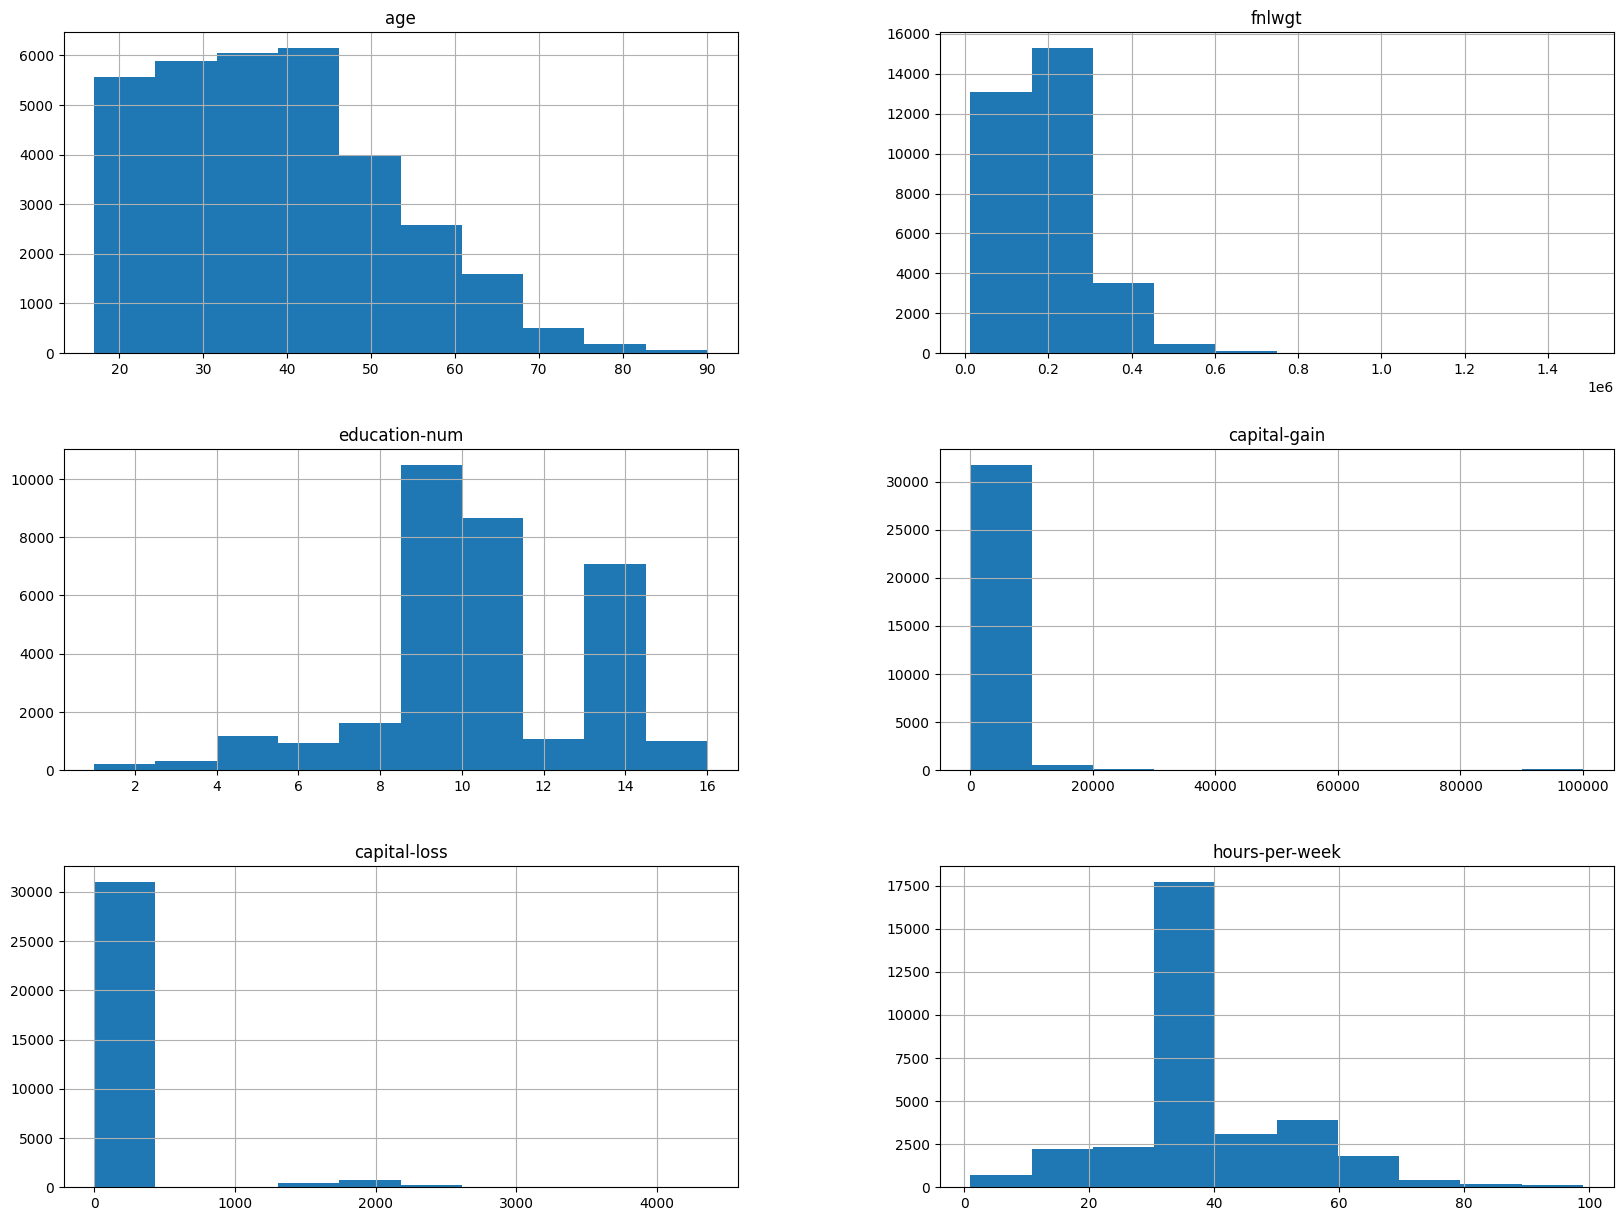

In [14]:
df.hist(figsize=(20, 15))
plt.show()

L'histogramme de `capital-gain` montre une seule grande barre à 0. Presque tout le monde a 0, et seules quelques personnes ont un montant.

C'est pour cette raison qu'on ne cherche pas à prédire le **montant** exact, mais seulement **si la personne a des gains ou non** (oui / non).

# Partie 2 : Création de la cible et des nouvelles variables

## Pourquoi cette partie vient avant la matrice de corrélation ?

* La variable cible n'est pas trouvée par la matrice : elle est **imposée par l'objectif métier** (ligne 6 du tableau).
* Notre cible (« a des gains : oui / non ») **n'existe pas encore** dans le fichier. Il faut la créer pour que la matrice puisse mesurer le lien entre les variables et la cible.
* Les nouvelles variables demandées (tranche d'âge, marié, niveau d'études regroupé) doivent aussi être créées **avant** la matrice, pour pouvoir vérifier si elles sont utiles.

## Créer la variable cible

On crée une nouvelle colonne `has_capital_gain` :
* **1** si `capital-gain` est supérieur à 0 (la personne a des gains en capital) ;
* **0** sinon.

In [15]:
df['has_capital_gain'] = (df['capital-gain'] > 0).astype(int)
target = 'has_capital_gain'

df[target].value_counts()

,count
has_capital_gain,
0,29825
1,2712


On affiche la proportion de chaque classe en pourcentage.

In [16]:
df[target].value_counts(normalize=True) * 100

,proportion
has_capital_gain,
0,91.664874
1,8.335126


On visualise la répartition de la cible.

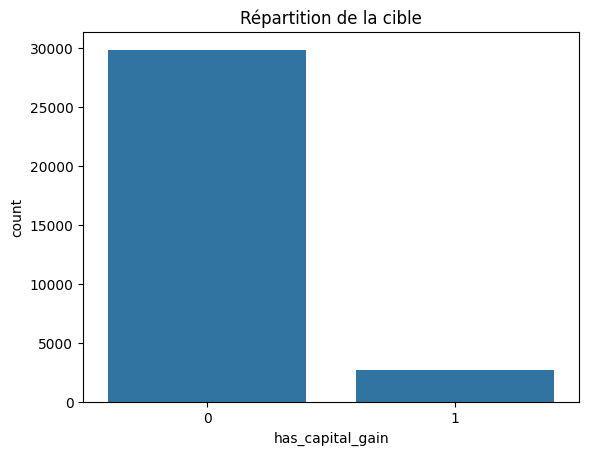

In [17]:
sns.countplot(x=target, data=df)
plt.title("Répartition de la cible")
plt.show()

Seulement environ **8 %** des personnes ont des gains en capital. On dit que la cible est **déséquilibrée**.

C'est important pour la suite : un modèle qui répond toujours « non » aurait 92 % de bonnes réponses tout en étant inutile. Lors de la modélisation, il faudra donc regarder d'autres mesures que l'accuracy (par exemple le rappel ou le F1-score).

## Nouvelle variable 1 : la tranche d'âge

On découpe l'âge en groupes : 17-25, 26-35, 36-45, 46-55, 56-65 et 66+.

**Pourquoi ?** On s'attend à ce que l'épargne augmente avec l'âge, car une personne plus âgée a eu plus de temps pour économiser et investir.

In [18]:
df['tranche_age'] = pd.cut(df['age'],
                           bins=[16, 25, 35, 45, 55, 65, 100],
                           labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+'])

df[['age', 'tranche_age']].head()

,age,tranche_age
0,39,36-45
1,50,46-55
2,38,36-45
3,53,46-55
4,28,26-35


## Nouvelle variable 2 : l'indicateur « marié »

On crée une colonne `est_marie` :
* **1** si la personne est mariée (`Married-civ-spouse` ou `Married-AF-spouse`) ;
* **0** sinon.

**Pourquoi ?** Un couple marié a souvent une épargne commune et des placements.

In [19]:
df['est_marie'] = df['marital-status'].isin(['Married-civ-spouse', 'Married-AF-spouse']).astype(int)

df[['marital-status', 'est_marie']].head()

,marital-status,est_marie
0,Never-married,0
1,Married-civ-spouse,1
2,Divorced,0
3,Married-civ-spouse,1
4,Married-civ-spouse,1


## Nouvelle variable 3 : le niveau d'études regroupé

La colonne `education` contient 16 niveaux différents, ce qui est beaucoup. On les regroupe en 5 niveaux en utilisant `education-num` (le niveau d'études sous forme de nombre, de 1 à 16) :

| education-num | Groupe |
|---|---|
| 1 à 8 | 1-Sans diplôme secondaire |
| 9 | 2-HS-grad (équivalent du bac) |
| 10 à 12 | 3-Études sup. courtes |
| 13 | 4-Bachelors (licence) |
| 14 à 16 | 5-Master et plus |

**Pourquoi ?** Moins de catégories rend la variable plus simple à utiliser et à interpréter.

In [20]:
def regrouper_education(n):
    if n <= 8:
        return '1-Sans diplome secondaire'
    elif n == 9:
        return '2-HS-grad'
    elif n <= 12:
        return '3-Etudes sup. courtes'
    elif n == 13:
        return '4-Bachelors'
    else:
        return '5-Master et plus'

df['education_groupe'] = df['education-num'].apply(regrouper_education)

df[['education', 'education-num', 'education_groupe']].head()

,education,education-num,education_groupe
0,Bachelors,13,4-Bachelors
1,Bachelors,13,4-Bachelors
2,HS-grad,9,2-HS-grad
3,11th,7,1-Sans diplome secondaire
4,Bachelors,13,4-Bachelors


## Vérifier que les nouvelles variables sont utiles

Pour chaque nouvelle variable, on calcule le **pourcentage de personnes qui ont des gains en capital** dans chaque groupe. La ligne rouge représente la moyenne générale (environ 8 %).

Si les barres sont très différentes les unes des autres, cela veut dire que la variable aide à distinguer les personnes qui ont des gains de celles qui n'en ont pas.

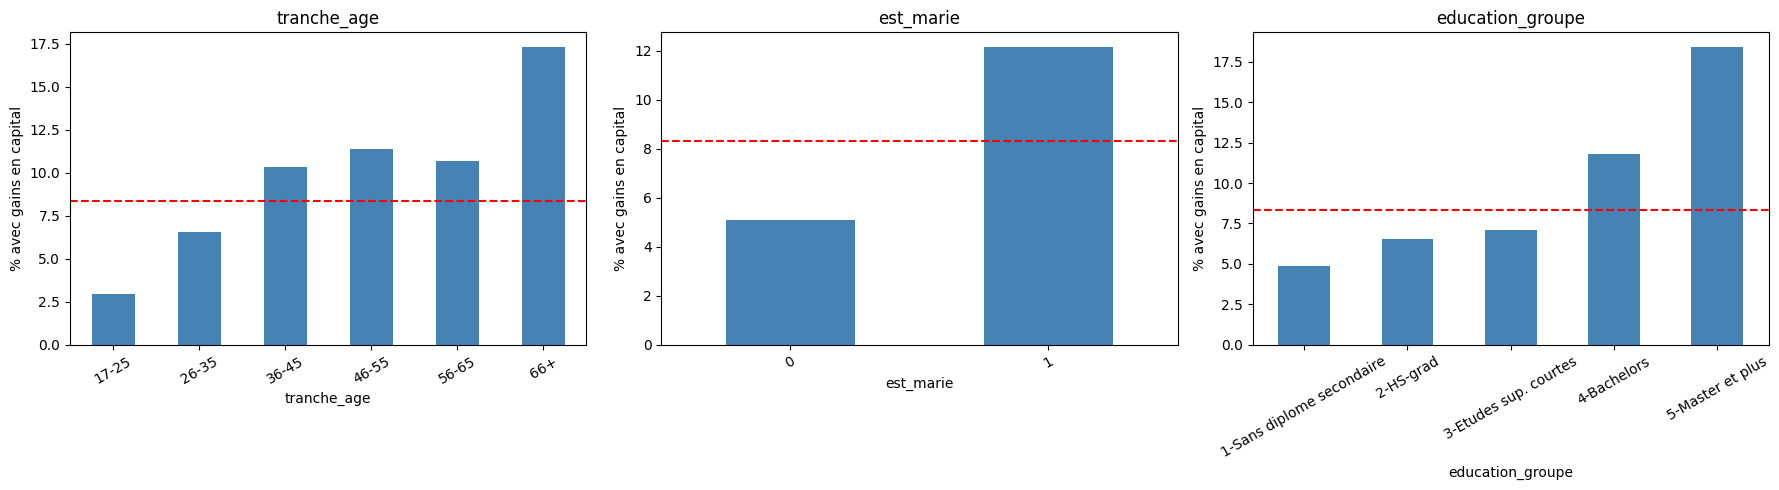

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['tranche_age', 'est_marie', 'education_groupe']):
    taux = df.groupby(col, observed=True)[target].mean() * 100
    taux.plot(kind='bar', ax=ax, color='steelblue')
    ax.axhline(df[target].mean() * 100, color='red', linestyle='--')
    ax.set_title(col)
    ax.set_ylabel("% avec gains en capital")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Lecture des graphiques :**
* **Tranche d'âge :** environ 3 % chez les 17-25 ans, contre environ 16 % chez les 66 ans et plus.
* **Marié :** environ 12 % chez les mariés, contre 5 % chez les autres.
* **Niveau d'études :** environ 5 % sans diplôme secondaire, contre environ 18 % pour Master et plus.

Les trois nouvelles variables sont donc **utiles** pour notre cible.

## Retirer les variables qui « trichent » (fuite de données)

Une **fuite de données** se produit quand une variable contient déjà la réponse. Le modèle semblerait très bon pendant l'entraînement, mais il serait inutilisable dans la réalité.

On retire :
* **`capital-gain`** : c'est elle qui a servi à créer la cible. La garder reviendrait à donner directement la réponse au modèle.
* **`capital-loss`** : on vérifie juste en dessous qu'une personne qui a une perte en capital n'a **jamais** de gain. Le recensement n'enregistre qu'un seul montant (gain ou perte). Cette variable vient donc de la même information que la cible.
* **`income`** : le revenu inclut les gains en capital. Un gros gain fait automatiquement passer le revenu au-dessus de 50K. De plus, l'organisme ne connaît pas le revenu des personnes qu'il veut cibler.
* **`fnlwgt`** : c'est un poids statistique utilisé par le recensement. Il ne décrit pas la personne.

Vérification pour `capital-loss` : on croise « a une perte » avec « a un gain ».

In [22]:
pd.crosstab(df['capital-loss'] > 0, df[target])

has_capital_gain,0,1
capital-loss,,
False,28306,2712
True,1519,0


Dans la ligne `True` (personnes avec une perte), la colonne `1` vaut **0** : aucune personne avec une perte n'a de gain. Cela confirme la fuite de données.

On supprime maintenant ces quatre colonnes.

In [23]:
df = df.drop(columns=['capital-gain', 'capital-loss', 'income', 'fnlwgt'])
df.columns

Index(['age', 'workclass', 'education', 'education-num', 'marital-status',
       'occupation', 'relationship', 'race', 'sex', 'hours-per-week',
       'native-country', 'has_capital_gain', 'tranche_age', 'est_marie',
       'education_groupe'],
      dtype='object')

## Retirer les variables en double

Certaines variables contiennent la même information qu'une nouvelle variable que l'on a créée. On garde une seule variable par information, et on choisit la version créée :

| Information | On garde | On retire |
|---|---|---|
| Âge | `tranche_age` | `age` |
| Niveau d'études | `education_groupe` | `education`, `education-num` |
| Situation familiale | `est_marie` | `marital-status`, `relationship` |

`relationship` est retirée car ses valeurs principales (`Husband`, `Wife`) indiquent simplement que la personne est mariée.

In [24]:
df = df.drop(columns=['age', 'education', 'education-num', 'marital-status', 'relationship'])
df.columns

Index(['workclass', 'occupation', 'race', 'sex', 'hours-per-week',
       'native-country', 'has_capital_gain', 'tranche_age', 'est_marie',
       'education_groupe'],
      dtype='object')

# Partie 3 : Transformation des données

## Encodage des variables texte

Les modèles et la matrice de corrélation ne comprennent que les nombres. On transforme donc chaque variable texte en nombres avec `LabelEncoder` (par exemple `Female` devient 0 et `Male` devient 1), comme dans le TP.

On garde une copie `df_texte` des données en texte, car on en aura besoin à la Partie 4.

In [25]:
df['tranche_age'] = df['tranche_age'].astype(str)
df_texte = df.copy()

colonnes_texte = ['workclass', 'occupation', 'race', 'sex', 'native-country', 'tranche_age', 'education_groupe']

for col in colonnes_texte:
    df[col] = LabelEncoder().fit_transform(df[col])

df.head()

,workclass,occupation,race,sex,hours-per-week,native-country,has_capital_gain,tranche_age,est_marie,education_groupe
0,6,0,4,1,40,38,1,2,0,3
1,5,3,4,1,13,38,0,3,1,3
2,3,5,4,1,40,38,0,2,0,1
3,3,5,2,1,40,38,0,3,1,0
4,3,9,2,0,40,4,0,1,1,3


## Normalisation

On met toutes les variables sur la même échelle (moyenne 0, écart-type 1) avec `StandardScaler`, comme dans le TP. Par exemple, `hours-per-week` va de 1 à 99 alors que `est_marie` vaut 0 ou 1.

On ne normalise pas la cible, car elle doit rester 0 ou 1.

In [26]:
df_normalized = df.copy()
colonnes = df.columns.drop(target)
df_normalized[colonnes] = StandardScaler().fit_transform(df[colonnes])

df_normalized.head()

,workclass,occupation,race,sex,hours-per-week,native-country,has_capital_gain,tranche_age,est_marie,education_groupe
0,1.876197,-1.483535,0.393685,0.703020,-0.035664,0.257437,1,0.145212,-0.924443,1.107560
1,1.175970,-0.790564,0.393685,0.703020,-2.222483,0.257437,0,0.878531,1.081733,1.107560
2,-0.224485,-0.328584,0.393685,0.703020,-0.035664,0.257437,0,0.145212,-0.924443,-0.661025
3,-0.224485,-0.328584,-1.962488,0.703020,-0.035664,0.257437,0,0.878531,1.081733,-1.545317
4,-0.224485,0.595376,-1.962488,-1.422436,-0.035664,-5.352003,0,-0.588106,1.081733,1.107560


# Partie 4 : Sélection des caractéristiques

## Matrice de corrélation

La matrice de corrélation montre le lien entre chaque paire de variables. Une valeur proche de **1** ou **-1** indique un lien fort, une valeur proche de **0** indique un lien faible.

On s'intéresse surtout à la **dernière ligne/colonne**, celle de la cible `has_capital_gain`.

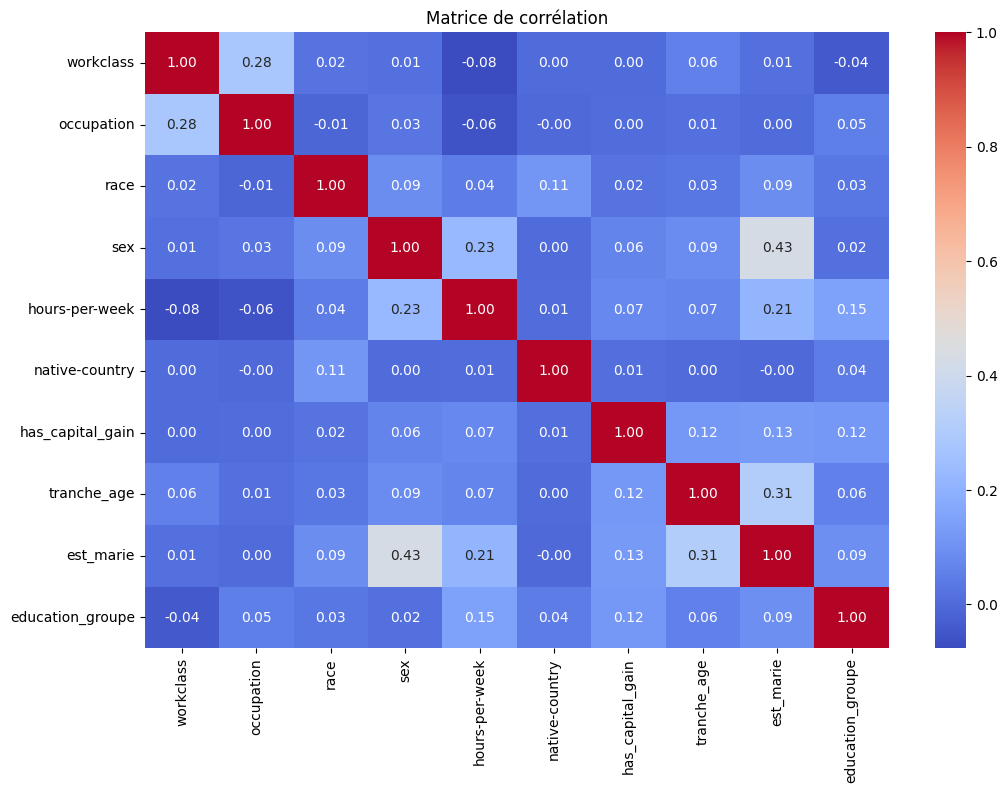

In [27]:
plt.figure(figsize=(12, 8))
corr_matrix = df_normalized.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matrice de corrélation')
plt.show()

## Corrélations avec la cible

On affiche uniquement la corrélation de chaque variable avec la cible. On prend la valeur absolue, car un lien négatif fort est aussi utile qu'un lien positif fort.

In [28]:
corr_matrix[target].abs().drop(target).sort_values(ascending=False)

,has_capital_gain
est_marie,0.127441
education_groupe,0.119634
tranche_age,0.118966
hours-per-week,0.074979
sex,0.064760
race,0.023615
native-country,0.011516
occupation,0.004422
workclass,0.000200


## Limite de la corrélation pour les variables texte

La corrélation fonctionne bien pour les variables qui sont de **vrais nombres** (`hours-per-week`) ou qui n'ont que **deux valeurs** (`est_marie`, `sex`).

Mais pour une variable texte avec beaucoup de catégories, comme `occupation`, le `LabelEncoder` a donné les numéros 0, 1, 2… **par ordre alphabétique**. Ces numéros n'ont pas de sens : `Adm-clerical` = 0 n'est pas « plus petit » que `Sales` = 11. La corrélation calculée sur ces numéros n'est donc pas fiable.

**Solution :** pour ces variables, on utilise le **V de Cramér**. C'est l'équivalent de la corrélation pour les variables texte. Il se calcule à partir du test du khi-deux et donne une valeur entre **0** (aucun lien) et **1** (lien parfait). Il ne dépend pas de l'ordre des catégories.

In [29]:
def v_de_cramer(x, y):
    tableau = pd.crosstab(x, y)
    chi2 = chi2_contingency(tableau)[0]
    n = tableau.values.sum()
    return np.sqrt(chi2 / (n * (min(tableau.shape) - 1)))

## Tableau final des scores

On calcule un score pour chaque variable :
* **Corrélation** (Pearson, celle de la matrice) pour les variables numériques ou à deux valeurs : `hours-per-week`, `est_marie`, `sex`.
* **V de Cramér** pour les variables texte à plusieurs catégories : on utilise `df_texte`, la copie gardée avant l'encodage.

In [30]:
variables_numeriques = ['hours-per-week', 'est_marie', 'sex']
variables_texte = ['tranche_age', 'education_groupe', 'occupation', 'workclass', 'race', 'native-country']

scores = {}
for col in variables_numeriques:
    scores[col] = abs(corr_matrix.loc[col, target])
for col in variables_texte:
    scores[col] = v_de_cramer(df_texte[col], df_texte[target])

scores = pd.Series(scores).sort_values(ascending=False).round(3)
scores

,0
education_groupe,0.133
tranche_age,0.128
est_marie,0.127
occupation,0.122
hours-per-week,0.075
workclass,0.073
sex,0.065
native-country,0.044
race,0.032


**Remarque importante :** dans la matrice de corrélation, `occupation` avait un score presque nul (environ 0.002), alors qu'avec le V de Cramér son score est d'environ 0.12. Cela montre bien que la corrélation calculée sur des numéros arbitraires peut cacher une variable utile.

On visualise ces scores. La ligne verte (0.10) est le seuil des variables **principales**, la ligne orange (0.05) le seuil des variables **secondaires**.

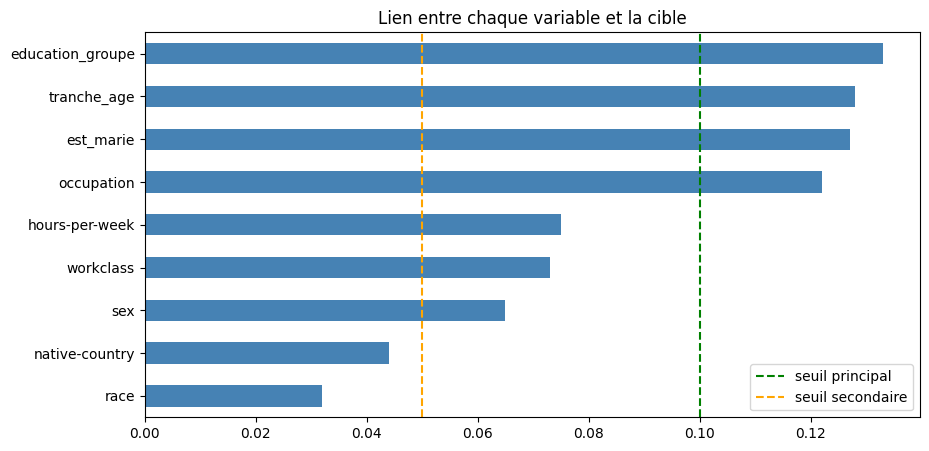

In [31]:
plt.figure(figsize=(10, 5))
scores.sort_values().plot(kind='barh', color='steelblue')
plt.axvline(0.10, color='green', linestyle='--', label='seuil principal')
plt.axvline(0.05, color='orange', linestyle='--', label='seuil secondaire')
plt.title("Lien entre chaque variable et la cible")
plt.legend()
plt.show()

## Choisir les caractéristiques principales et secondaires

On applique deux seuils, comme le seuil de 0.1 utilisé dans le TP :
* **Principales :** score supérieur ou égal à **0.10** (lien clair avec la cible).
* **Secondaires :** score entre **0.05** et **0.10** (lien plus faible mais présent).
* **Écartées :** score inférieur à **0.05** (lien trop faible).
* **Écartée d'office :** `sex`, car c'est une **variable sensible**. L'utiliser pour cibler des actions pourrait être discriminant. C'est aussi la règle commune du groupe (le tableau des objectifs exclut les variables sensibles). `race` et `native-country` sont déjà écartées car leur lien est trop faible.

In [32]:
features_principales = scores[scores >= 0.10].index.tolist()
features_secondaires = scores[(scores >= 0.05) & (scores < 0.10)].index.tolist()
features_ecartees = scores[scores < 0.05].index.tolist()

variables_sensibles = ['sex']
features_secondaires = [f for f in features_secondaires if f not in variables_sensibles]

print("Principales :", features_principales)
print("Secondaires :", features_secondaires)
print("Écartées    :", features_ecartees)
print("Écartées (variables sensibles) :", variables_sensibles)

Principales : ['education_groupe', 'tranche_age', 'est_marie', 'occupation']
Secondaires : ['hours-per-week', 'workclass']
Écartées    : ['native-country', 'race']
Écartées (variables sensibles) : ['sex']


## Conclusion de la sélection

| Rôle | Variable | Explication |
|---|---|---|
| **Principale** | `education_groupe` | Plus le niveau d'études est élevé, plus on a de gains en capital |
| **Principale** | `tranche_age` | Les personnes plus âgées ont plus souvent des gains |
| **Principale** | `est_marie` | Les personnes mariées ont deux fois plus souvent des gains |
| **Principale** | `occupation` | Les cadres et professions intellectuelles ont plus souvent des gains |
| **Secondaire** | `hours-per-week` | Lien plus faible avec la cible |
| **Secondaire** | `workclass` | Les indépendants ont plus souvent des gains |
| Écartée | `sex` | Variable sensible : exclue pour éviter un ciblage discriminant (règle commune du groupe) |
| Écartée | `race`, `native-country` | Lien trop faible, et ce sont des variables sensibles |
| Écartée | `capital-gain`, `capital-loss`, `income` | Fuite de données |
| Écartée | `fnlwgt` | Poids statistique sans signification pour la personne |

Les trois variables créées (tranche d'âge, marié, niveau d'études regroupé) font toutes partie des variables **principales**. Cela confirme les choix de l'objectif Data Science.

## Créer le DataFrame avec les caractéristiques sélectionnées

On garde uniquement les variables principales et secondaires, plus la cible, comme à la fin du TP.

In [33]:
df_selected = df_normalized[features_principales + features_secondaires + [target]]
df_selected.head()

,education_groupe,tranche_age,est_marie,occupation,hours-per-week,workclass,has_capital_gain
0,1.107560,0.145212,-0.924443,-1.483535,-0.035664,1.876197,1
1,1.107560,0.878531,1.081733,-0.790564,-2.222483,1.175970,0
2,-0.661025,0.145212,-0.924443,-0.328584,-0.035664,-0.224485,0
3,-1.545317,0.878531,1.081733,-0.328584,-0.035664,-0.224485,0
4,1.107560,-0.588106,1.081733,0.595376,-0.035664,-0.224485,0


Enfin, on sépare les variables explicatives **X** et la cible **y**. Ce sont les données qui serviront à entraîner le modèle de classification à l'étape suivante.

In [34]:
X = df_selected.drop(columns=[target])
y = df_selected[target]

print("X :", X.shape)
print("y :", y.shape)

X : (32537, 6)
y : (32537,)


# Partie 5 : Modélisation (classification binaire)

**Objectif :** prédire si une personne a des gains en capital (`has_capital_gain` = 1) ou non (0).

**Type de problème :** c'est une **classification binaire**, car la cible n'a que deux valeurs. Pour résoudre ce problème, on compare **cinq algorithmes de classification binaire** et on retient le plus adapté.

**Démarche :**
1. Préparer les données d'entraînement et de test.
2. Tester **5 algorithmes** de classification binaire.
3. Les comparer avec des métriques adaptées à notre problème.
4. Choisir le modèle le plus adapté au **but de l'organisme d'éducation financière**.

**Ce qu'on attend, d'après la Partie 4 :** les scores de lien avec la cible sont faibles (environ 0.13 au maximum). Aucune variable ne permet à elle seule de savoir si une personne a des gains en capital. On ne doit donc **pas** espérer un modèle très précis. L'objectif réaliste est d'obtenir un modèle qui **classe les personnes de la plus probable à la moins probable**, pour que l'organisme cible en priorité les bons profils.

## Importer les outils de modélisation

* `train_test_split` : séparer les données en entraînement et test.
* `cross_validate` et `StratifiedKFold` : la validation croisée.
* `Pipeline` et `ColumnTransformer` : enchaîner la préparation et le modèle.
* `OneHotEncoder` : encoder les variables texte.
* Les 5 algorithmes : `DecisionTreeClassifier`, `RandomForestClassifier`, `HistGradientBoostingClassifier`, `KNeighborsClassifier`, `BernoulliNB`.
* `permutation_importance` : mesurer l'importance de chaque variable.
* `metrics` : les mesures de performance.

In [35]:
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import make_scorer
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

## Pourquoi on repart de `df_texte` et pas de `df_selected`

`df_selected` contient deux problèmes pour la modélisation :

1. **Le `LabelEncoder` crée un faux ordre.** Pour `occupation`, le métier n°11 n'est pas « plus grand » que le métier n°0. Un modèle pourrait pourtant utiliser ces numéros comme des quantités (par exemple « métier > 5 »). On utilise donc le **One-Hot Encoding** : une colonne 0/1 par catégorie.
2. **La normalisation a été calculée sur toutes les données**, y compris celles qui serviront au test. Le modèle aurait donc « vu » une information sur le jeu de test. Ici, la normalisation sera apprise **uniquement sur l'entraînement** grâce au `Pipeline`.

On garde exactement les **mêmes variables** que celles choisies à la Partie 4 (principales et secondaires).

In [36]:
variables_categorielles = [c for c in features_principales + features_secondaires if c in variables_texte or c == 'sex']
variables_numeriques_modele = [c for c in features_principales + features_secondaires if c not in variables_categorielles]

X = df_texte[variables_categorielles + variables_numeriques_modele]
y = df_texte[target]

print("Variables catégorielles :", variables_categorielles)
print("Variables numériques    :", variables_numeriques_modele)
print("X :", X.shape, "| y :", y.shape)

Variables catégorielles : ['education_groupe', 'tranche_age', 'occupation', 'workclass']
Variables numériques    : ['est_marie', 'hours-per-week']
X : (32537, 6) | y : (32537,)


## Équilibrer les données (sous-échantillonnage)

**Pourquoi ?** On veut évaluer les modèles avec l'**accuracy** (le pourcentage de bonnes réponses). Mais dans les données réelles, 92 % des personnes n'ont pas de gains. Un modèle qui répond toujours « non » aurait donc déjà 92 % d'accuracy sans rien apprendre. L'accuracy ne permettrait pas de distinguer un bon modèle d'un modèle inutile.

**Solution :** on crée un jeu de données **équilibré** :
* on garde **toutes** les personnes avec gains en capital ;
* on tire **au hasard** le même nombre de personnes sans gains (`sample`, avec `random_state=42` pour obtenir toujours le même tirage) ;
* on mélange les lignes.

On obtient 50 % de « oui » et 50 % de « non ». Un modèle qui répond toujours « non » n'a plus que 50 % d'accuracy : l'accuracy redevient une mesure fiable.

On garde une copie des données réelles (`X_brut`, `y_brut`) pour montrer le problème juste après.

In [37]:
X_brut = X.copy()
y_brut = y.copy()

avec_gains = df_texte[df_texte[target] == 1]
sans_gains = df_texte[df_texte[target] == 0].sample(n=len(avec_gains), random_state=42)
donnees_equilibrees = pd.concat([avec_gains, sans_gains]).sample(frac=1, random_state=42)

X = donnees_equilibrees[variables_categorielles + variables_numeriques_modele]
y = donnees_equilibrees[target]

print("Avant équilibrage :", len(y_brut), "personnes")
print("Après équilibrage :", len(y), "personnes")
print(y.value_counts())

Avant équilibrage : 32537 personnes
Après équilibrage : 5424 personnes
has_capital_gain
0    2712
1    2712
Name: count, dtype: int64


## Séparer les données : entraînement (80 %) et test (20 %)

* Le jeu d'**entraînement** sert à apprendre et à comparer les modèles.
* Le jeu de **test** est mis de côté. On ne l'utilise qu'**une seule fois**, à la fin, pour vérifier le modèle choisi sur des personnes qu'il n'a jamais vues.

`stratify=y` garde la même proportion de « oui » et de « non » (50 % / 50 %) dans les deux jeux.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Entraînement :", X_train.shape, "- taux de positifs :", round(y_train.mean() * 100, 2), "%")
print("Test         :", X_test.shape, "- taux de positifs :", round(y_test.mean() * 100, 2), "%")

Entraînement : (4339, 6) - taux de positifs : 50.01 %
Test         : (1085, 6) - taux de positifs : 49.95 %


## Préparation automatique des données

Le `ColumnTransformer` applique :
* le **One-Hot Encoding** aux variables texte ;
* la **normalisation** (`StandardScaler`) aux variables numériques.

Il sera placé dans un `Pipeline` avec chaque modèle. Ainsi, la préparation est apprise sur l'entraînement seulement, puis appliquée telle quelle au test.

In [39]:
preparation = ColumnTransformer([
    ('texte', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variables_categorielles),
    ('nombres', StandardScaler(), variables_numeriques_modele)
])

## Le piège de l'accuracy sur les données réelles

On compare l'accuracy d'un « modèle » qui répond **toujours non** (personne n'a de gains) sur les données réelles et sur les données équilibrées.

In [40]:
print("Données réelles     -> accuracy du modèle « toujours non » :", round((y_brut == 0).mean(), 3))
print("Données équilibrées -> accuracy du modèle « toujours non » :", round((y_test == 0).mean(), 3))

Données réelles     -> accuracy du modèle « toujours non » : 0.917
Données équilibrées -> accuracy du modèle « toujours non » : 0.5


* Sur les données **réelles**, ce « modèle » obtient **92 %** d'accuracy alors qu'il ne trouve aucune personne avec gains.
* Sur les données **équilibrées**, il n'obtient que **50 %**, c'est-à-dire le hasard.

Vérifions avec un vrai modèle : on entraîne une Random Forest sur les données **réelles**, sans équilibrage, et on regarde son accuracy et son rappel (la part des personnes avec gains qu'il trouve).

In [41]:
rf_brut = Pipeline([('preparation', preparation),
                    ('modele', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))])

scores_brut = cross_validate(rf_brut, X_brut, y_brut, scoring=['accuracy', 'recall'],
                             cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))

print("Random Forest sur les données réelles :")
print("Accuracy :", round(scores_brut['test_accuracy'].mean(), 3))
print("Rappel   :", round(scores_brut['test_recall'].mean(), 3))

Random Forest sur les données réelles :
Accuracy : 0.917
Rappel   : 0.001


La Random Forest entraînée sur les données réelles obtient **91.7 %** d'accuracy, mais un **rappel presque nul** (0.001) : elle a appris à répondre presque toujours « non ». C'est la manière la plus simple d'avoir une bonne accuracy quand 92 % des réponses sont « non ». Ce modèle est inutile pour l'organisme.

**Conclusion :** sur les données réelles, l'accuracy est trompeuse. C'est pourquoi on travaille sur les **données équilibrées**. Dans ce cas :
* le hasard correspond à une accuracy de **0.50** ;
* un modèle est utile si son accuracy est **nettement au-dessus de 0.50**.

L'**accuracy** est notre mesure principale. On affiche aussi trois mesures complémentaires :

| Mesure | Question à laquelle elle répond |
|---|---|
| **Accuracy** | Quel pourcentage de personnes le modèle classe-t-il correctement ? |
| **Rappel (recall)** | Parmi les personnes qui ont vraiment des gains, combien le modèle en trouve-t-il ? |
| **Précision** | Parmi les personnes que le modèle cible, combien ont vraiment des gains ? |
| **F1-score** | Un équilibre entre le rappel et la précision |
| **ROC-AUC** | Le modèle classe-t-il bien les personnes de la plus probable à la moins probable ? (0.5 = hasard, 1 = parfait) |

## Les 5 algorithmes testés

| Algorithme | Principe | Pourquoi le tester |
|---|---|---|
| **Arbre de décision** | Pose une suite de questions (« marié ? », « plus de 45 ans ? »…) pour arriver à une réponse | Le plus simple et le plus facile à expliquer |
| **Random Forest** | Construit 300 arbres différents et fait voter leurs réponses | Plus stable qu'un seul arbre, moins de risque de sur-apprentissage |
| **Gradient Boosting** | Construit des arbres l'un après l'autre, chacun corrigeant les erreurs du précédent | Souvent le plus performant sur des données en tableau |
| **K plus proches voisins (KNN)** | Regarde les 50 personnes au profil le plus proche et prend la réponse majoritaire | Méthode très différente des arbres, basée sur la ressemblance entre profils |
| **Naive Bayes** | Calcule une probabilité avec la formule de Bayes, en supposant les variables indépendantes | Très rapide, bien adapté aux variables 0/1 créées par le One-Hot Encoding |

Comme les données sont maintenant **équilibrées**, on n'a plus besoin d'options spéciales pour gérer le déséquilibre (comme `class_weight='balanced'`).

**Limiter le sur-apprentissage :** on limite la profondeur des arbres (`max_depth`) et le nombre minimum de personnes par feuille (`min_samples_leaf`). Sinon les arbres apprennent les données d'entraînement par cœur.

In [42]:
modeles = {
    'Arbre de décision': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                                            random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                                        random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=50),
    'Naive Bayes': BernoulliNB()
}

## Comparaison par validation croisée (5 plis)

La validation croisée découpe le jeu d'entraînement en 5 parties. Le modèle est entraîné 5 fois sur 4 parties et évalué sur la partie restante. On fait ensuite la moyenne des 5 scores.

C'est plus fiable qu'un seul essai, et cela permet de **choisir le modèle sans toucher au jeu de test**.

On affiche aussi l'accuracy sur les données d'**entraînement** : si elle est beaucoup plus haute que celle de la validation, le modèle a appris par cœur (sur-apprentissage).

In [43]:
validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mesures = {'Accuracy': 'accuracy', 'Rappel': 'recall', 'Précision': make_scorer(precision_score, zero_division=0),
           'F1': 'f1', 'ROC-AUC': 'roc_auc'}

resultats = {}
for nom, modele in modeles.items():
    pipeline = Pipeline([('preparation', preparation), ('modele', modele)])
    scores_cv = cross_validate(pipeline, X_train, y_train, cv=validation, scoring=mesures, return_train_score=True)
    resultats[nom] = {m: scores_cv['test_' + m].mean() for m in mesures}
    resultats[nom]['Accuracy entraînement'] = scores_cv['train_Accuracy'].mean()

tableau_cv = pd.DataFrame(resultats).T.round(3)
tableau_cv

,Accuracy,Rappel,Précision,F1,ROC-AUC,Accuracy entraînement
Arbre de décision,0.631,0.668,0.624,0.644,0.686,0.651
Random Forest,0.651,0.697,0.639,0.666,0.706,0.670
Gradient Boosting,0.641,0.676,0.632,0.653,0.694,0.694
KNN,0.641,0.632,0.644,0.638,0.689,0.654
Naive Bayes,0.640,0.646,0.639,0.642,0.699,0.644


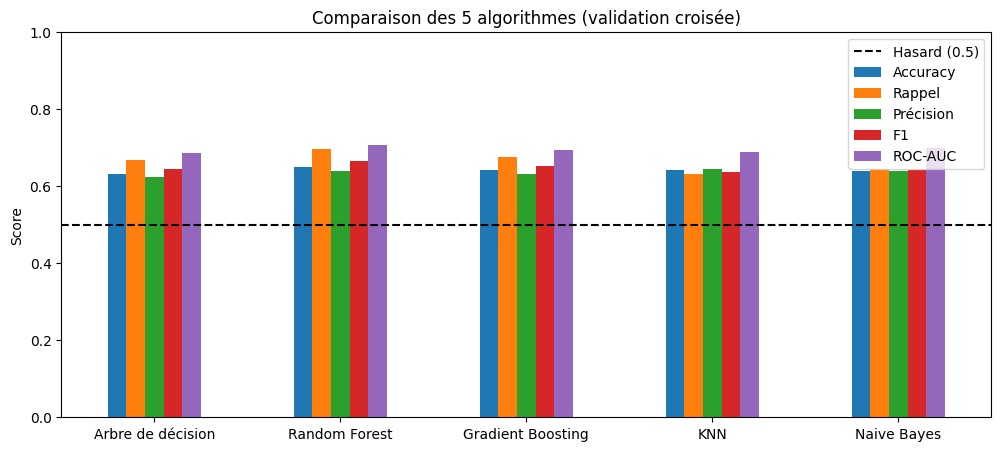

In [44]:
tableau_cv[['Accuracy', 'Rappel', 'Précision', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(12, 5))
plt.axhline(0.5, color='black', linestyle='--', label='Hasard (0.5)')
plt.title("Comparaison des 5 algorithmes (validation croisée)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.show()

## Lecture des résultats

* Les **5 algorithmes** ont une accuracy comprise entre **0.631** et **0.651**, nettement au-dessus du hasard (0.50). Ils apprennent donc tous quelque chose d'utile.
* La **Random Forest** obtient la **meilleure accuracy** (0.651), ainsi que le meilleur **F1** (0.666) et le meilleur **ROC-AUC** (0.706).
* L'**arbre de décision** seul est le moins bon (accuracy 0.631) : un seul arbre est trop simple.
* Le **Gradient Boosting**, **Naive Bayes** et le **KNN** sont proches (entre 0.637 et 0.641), mais en dessous de la Random Forest.
* Le **Gradient Boosting** montre le plus grand écart entre entraînement (0.694) et validation (0.641) : il commence à apprendre par cœur. La Random Forest a un écart plus faible (0.670 contre 0.651).

**Pourquoi l'accuracy reste modeste (environ 65 %) ?** C'est cohérent avec la Partie 4 : nos variables ont un lien faible avec la cible (environ 0.13). Avoir des gains en capital dépend surtout d'informations absentes du dataset (patrimoine, héritage, épargne). Un modèle plus complexe ne peut pas inventer une information qui n'est pas dans les données.

## Choix du modèle : la Random Forest

On choisit la **Random Forest** pour trois raisons liées au but de l'organisme :

1. **Meilleure accuracy** des 5 algorithmes en validation croisée (0.651).
2. **Meilleure aussi sur les autres mesures** : meilleur F1 et meilleur ROC-AUC, avec un bon rappel (elle trouve environ 70 % des personnes avec gains).
3. **Stable et interprétable** : elle fait voter 300 arbres, donc elle dépend peu des particularités des données, et on peut mesurer l'importance de chaque variable (voir plus bas).

In [45]:
modele_choisi = Pipeline([('preparation', preparation), ('modele', modeles['Random Forest'])])
modele_choisi.fit(X_train, y_train)

Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('texte',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['education_groupe',
                                                   'tranche_age', 'occupation',
                                                   'workclass']),
                                                 ('nombres', StandardScaler(),
                                                  ['est_marie',
                                                   'hours-per-week'])])),
                ('modele',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=20,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

## Évaluation finale sur le jeu de test

C'est la première et la seule fois qu'on utilise le jeu de test. Il simule de nouvelles personnes que l'organisme voudrait évaluer.

In [46]:
predictions = modele_choisi.predict(X_test)
probabilites = modele_choisi.predict_proba(X_test)[:, 1]

print("Accuracy  :", round(accuracy_score(y_test, predictions), 3))
print("Rappel    :", round(recall_score(y_test, predictions), 3))
print("Précision :", round(precision_score(y_test, predictions), 3))
print("F1        :", round(f1_score(y_test, predictions), 3))
print("ROC-AUC   :", round(roc_auc_score(y_test, probabilites), 3))

Accuracy  : 0.64
Rappel    : 0.683
Précision : 0.628
F1        : 0.654
ROC-AUC   : 0.681


Sur le jeu de test, la Random Forest obtient une **accuracy de 0.640**, soit environ **64 % de bonnes réponses**, contre 50 % pour le hasard.

C'est légèrement plus bas que la validation croisée (0.651), mais l'écart reste petit : le modèle se comporte à peu près de la même manière sur des personnes qu'il n'a jamais vues.

## Optimisation des hyperparamètres

Pour maximiser l'accuracy, on teste plusieurs réglages de la Random Forest avec `GridSearchCV` :
* `max_depth` : la profondeur maximale des arbres ;
* `min_samples_leaf` : le nombre minimum de personnes dans chaque feuille ;
* `max_features` : la part des variables utilisée à chaque question de l'arbre.

GridSearchCV essaie toutes les combinaisons (40 au total) avec la validation croisée, et garde celle qui donne la meilleure accuracy. On utilise uniquement le jeu d'entraînement.

(Cette cellule peut prendre 2 à 3 minutes.)

In [47]:
from sklearn.model_selection import GridSearchCV

grille = {
    'modele__max_depth': [5, 8, 10, 15, None],
    'modele__min_samples_leaf': [5, 10, 20, 50],
    'modele__max_features': ['sqrt', 0.5]
}

recherche = GridSearchCV(modele_choisi, grille, cv=validation, scoring='accuracy', n_jobs=-1)
recherche.fit(X_train, y_train)

print("Meilleurs paramètres :", recherche.best_params_)
print("Accuracy en validation croisée :", round(recherche.best_score_, 3))

Meilleurs paramètres : {'modele__max_depth': 15, 'modele__max_features': 'sqrt', 'modele__min_samples_leaf': 20}
Accuracy en validation croisée : 0.653


On compare l'accuracy sur le jeu de test avant et après l'optimisation.

In [48]:
modele_optimise = recherche.best_estimator_
predictions_optimise = modele_optimise.predict(X_test)

print("Accuracy sur le test avant optimisation :", round(accuracy_score(y_test, predictions), 3))
print("Accuracy sur le test après optimisation :", round(accuracy_score(y_test, predictions_optimise), 3))

Accuracy sur le test avant optimisation : 0.64
Accuracy sur le test après optimisation : 0.633


Les meilleurs paramètres trouvés sont max_depth = 15, min_samples_leaf = 20 et max_features = 'sqrt'. L'accuracy passe de 0.651 à 0.653 en validation croisée, mais elle **baisse** sur le test, de 0.640 à 0.633.

Le gain en validation croisée (0.002) est beaucoup plus petit que la variation d'un pli à l'autre (environ 0.014), et il disparaît sur le test : l'optimisation n'apporte **aucune amélioration réelle**. On garde donc le modèle de départ, plus simple et meilleur sur le test.

Cela confirme que la limite vient des données et non du modèle. Les variables disponibles ont un lien faible avec la cible (environ 0.13 dans la matrice de corrélation). Les seules variables qui feraient monter l'accuracy, `income` et `capital-loss`, sont des fuites de données : on ne peut pas les utiliser.

## Matrice de confusion

Elle montre, pour les personnes du test :
* en haut à gauche : sans gains, bien prédits « non » ;
* en bas à droite : avec gains, bien trouvés ;
* en bas à gauche : avec gains, **manqués** par le modèle ;
* en haut à droite : sans gains, ciblés à tort.

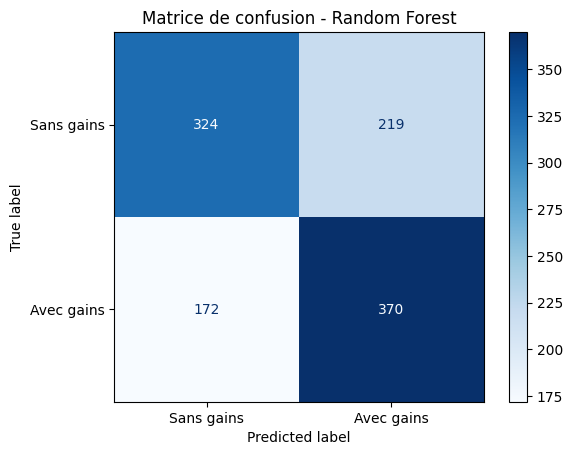

In [49]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=['Sans gains', 'Avec gains'], cmap='Blues')
plt.title("Matrice de confusion - Random Forest")
plt.show()

Le modèle classe correctement environ **64 %** des personnes. Il trouve environ **2 personnes avec gains sur 3** (rappel ≈ 0.68), et parmi les personnes qu'il cible, environ **63 %** ont vraiment des gains (précision ≈ 0.63).

Pour l'organisme, une action de sensibilisation à l'épargne coûte peu, et elle n'est pas nuisible pour une personne qui n'a pas encore de gains en capital. Les erreurs « ciblée à tort » (en haut à droite) sont donc moins graves que les personnes avec gains manquées (en bas à gauche).

## Courbe ROC

La courbe ROC montre la capacité du modèle à séparer les deux groupes. La diagonale correspond au hasard. Plus la courbe est au-dessus de la diagonale, meilleur est le modèle.

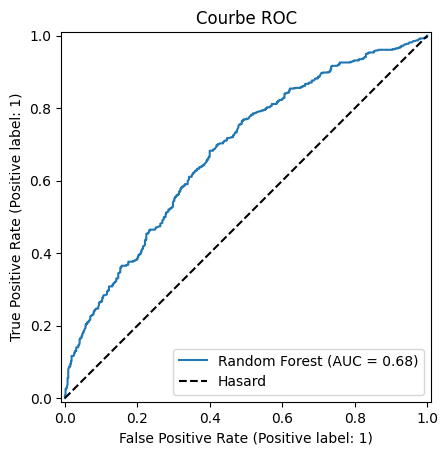

In [50]:
RocCurveDisplay.from_predictions(y_test, probabilites, name='Random Forest')
plt.plot([0, 1], [0, 1], 'k--', label='Hasard')
plt.legend()
plt.title("Courbe ROC")
plt.show()

## Utilisation concrète : cibler les profils les plus probables

Le modèle donne aussi une **probabilité** pour chaque personne. On peut donc classer les personnes de la plus probable à la moins probable. Si l'organisme ne contacte que les **20 %** de personnes du jeu de test jugées les plus probables, combien de personnes avec gains atteint-il ?

In [51]:
nombre_cible = int(len(probabilites) * 0.20)
indices_cibles = np.argsort(-probabilites)[:nombre_cible]

trouves = y_test.values[indices_cibles].sum()
total = y_test.sum()

print("Personnes contactées        :", nombre_cible, "(20 % de la population)")
print("Personnes avec gains        :", trouves, "sur", total)
print("Part des personnes trouvées :", round(trouves / total * 100, 1), "%")
print("Au hasard, on en trouverait : 20 %")

Personnes contactées        : 217 (20 % de la population)
Personnes avec gains        : 155 sur 542
Part des personnes trouvées : 28.6 %
Au hasard, on en trouverait : 20 %


En contactant les 20 % de personnes jugées les plus probables, l'organisme atteint **28 %** des personnes avec gains, contre 20 % au hasard. Parmi ces 217 personnes contactées, environ **71 %** ont vraiment des gains (154 sur 217), alors que la proportion est de 50 % dans le jeu de test.

Le modèle permet donc de **prioriser** les profils les plus intéressants pour les actions de sensibilisation.

## Interprétation : quelles variables comptent le plus ?

On utilise l'**importance par permutation** : on mélange au hasard les valeurs d'une variable, puis on regarde de combien l'**accuracy** baisse. Plus la baisse est forte, plus le modèle a besoin de cette variable.

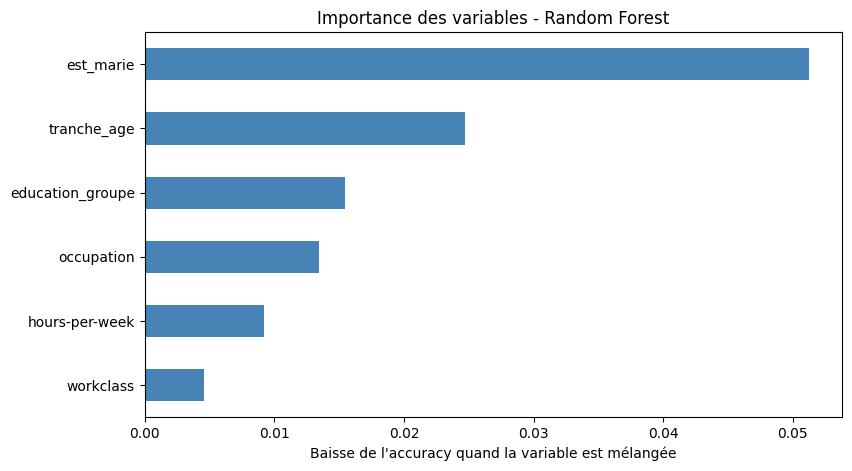

,0
est_marie,0.051
tranche_age,0.025
education_groupe,0.015
occupation,0.013
hours-per-week,0.009
workclass,0.005


In [52]:
importance = permutation_importance(modele_choisi, X_test, y_test, scoring='accuracy', n_repeats=5, random_state=42)
importance = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(9, 5))
importance.plot(kind='barh', color='steelblue')
plt.title("Importance des variables - Random Forest")
plt.xlabel("Baisse de l'accuracy quand la variable est mélangée")
plt.show()

importance.sort_values(ascending=False).round(3)

Les **3 variables les plus importantes** pour le modèle sont exactement celles de notre **objectif Data Science** : l'**indicateur « marié »**, la **tranche d'âge** et le **niveau d'études regroupé**. Cela confirme la sélection des caractéristiques faite à la Partie 4.

Les autres variables (`occupation`, `hours-per-week`, `workclass`) ont une importance plus faible : elles font baisser l'accuracy de moins de 1.5 point quand on les mélange.

# Conclusion

| Étape | Résultat |
|---|---|
| Type de problème | Classification binaire de `capital-gain > 0` |
| Mesure principale | **Accuracy**, calculée sur des données **équilibrées** (50 % / 50 %) |
| Pourquoi équilibrer | Sur les données réelles, un modèle qui répond toujours « non » obtient 92 % d'accuracy |
| Variables | Tranche d'âge, marié, niveau d'études (principales) ; métier, heures, type d'employeur (secondaires) ; `sex` exclue (variable sensible) |
| Algorithmes testés | Arbre de décision, Random Forest, Gradient Boosting, KNN, Naive Bayes |
| Performances | Accuracy entre 0.63 et 0.65 en validation croisée (hasard = 0.50) |
| Modèle choisi | **Random Forest** : meilleure accuracy, meilleurs F1 et ROC-AUC |
| Résultat sur le test | Accuracy de **0.640** (64 % de bonnes réponses) |
| Variables clés | Marié, tranche d'âge, niveau d'études regroupé (celles de l'objectif Data Science) |

**Limite :** les variables du dataset expliquent mal le fait d'avoir des gains en capital, comme le montrait la matrice de corrélation (liens ≈ 0.13). Pour améliorer le modèle, il faudrait des données supplémentaires sur le patrimoine ou l'épargne des personnes, et non un modèle plus complexe.

# Partie 6 : Évaluation approfondie du modèle choisi

À la Partie 5, on a choisi la **Random Forest** et calculé son accuracy. Cette partie vérifie plus en détail si le modèle est **fiable** et **adapté au but de l'organisme** :

1. Le rapport de classification complet.
2. La comparaison des 5 algorithmes sur le jeu de test.
3. La stabilité du modèle.
4. Le choix du seuil de décision.
5. La courbe de gain (efficacité du ciblage).
6. La courbe d'apprentissage (faut-il plus de données ?).
7. L'analyse par groupe de population (le modèle est-il équitable ?).

In [53]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, average_precision_score
from sklearn.model_selection import cross_val_predict, learning_curve

## 1. Rapport de classification

Ce rapport donne la précision, le rappel et le F1 **pour chaque classe** :
* classe **0** : personnes sans gains en capital ;
* classe **1** : personnes avec gains en capital (celles que l'organisme veut trouver).

In [54]:
print(classification_report(y_test, predictions, target_names=['Sans gains (0)', 'Avec gains (1)']))

                precision    recall  f1-score   support

Sans gains (0)       0.65      0.60      0.62       543
Avec gains (1)       0.63      0.68      0.65       542

      accuracy                           0.64      1085
     macro avg       0.64      0.64      0.64      1085
  weighted avg       0.64      0.64      0.64      1085



**Lecture :**
* L'**accuracy** est de **0.64** : le modèle classe correctement 64 % des personnes du test.
* Pour la classe 1 (avec gains), le **rappel est de 0.68** : le modèle trouve 68 % des personnes avec gains, et sa **précision est de 0.63**.
* Pour la classe 0 (sans gains), le rappel est de 0.60 et la précision de 0.65.
* Les scores des deux classes sont **proches** : grâce à l'équilibrage, le modèle ne favorise plus la classe « sans gains ». Il est même un peu meilleur pour trouver les personnes avec gains, ce qui correspond au besoin de l'organisme.

## 2. Comparaison des 5 algorithmes sur le jeu de test

À la Partie 5, la comparaison a été faite en validation croisée sur l'entraînement. On vérifie maintenant sur le jeu de test que la Random Forest reste parmi les meilleurs.

* L'**accuracy sur le test** est affichée pour chaque algorithme.
* **Courbe ROC** : plus la courbe est haute, mieux l'algorithme sépare les deux classes.
* **Courbe précision-rappel** : la ligne pointillée correspond au hasard (50 % de positifs). L'**AP** (précision moyenne) résume cette courbe.

Random Forest        0.640
KNN                  0.634
Arbre de décision    0.627
Gradient Boosting    0.618
Naive Bayes          0.615
Name: Accuracy sur le test, dtype: float64


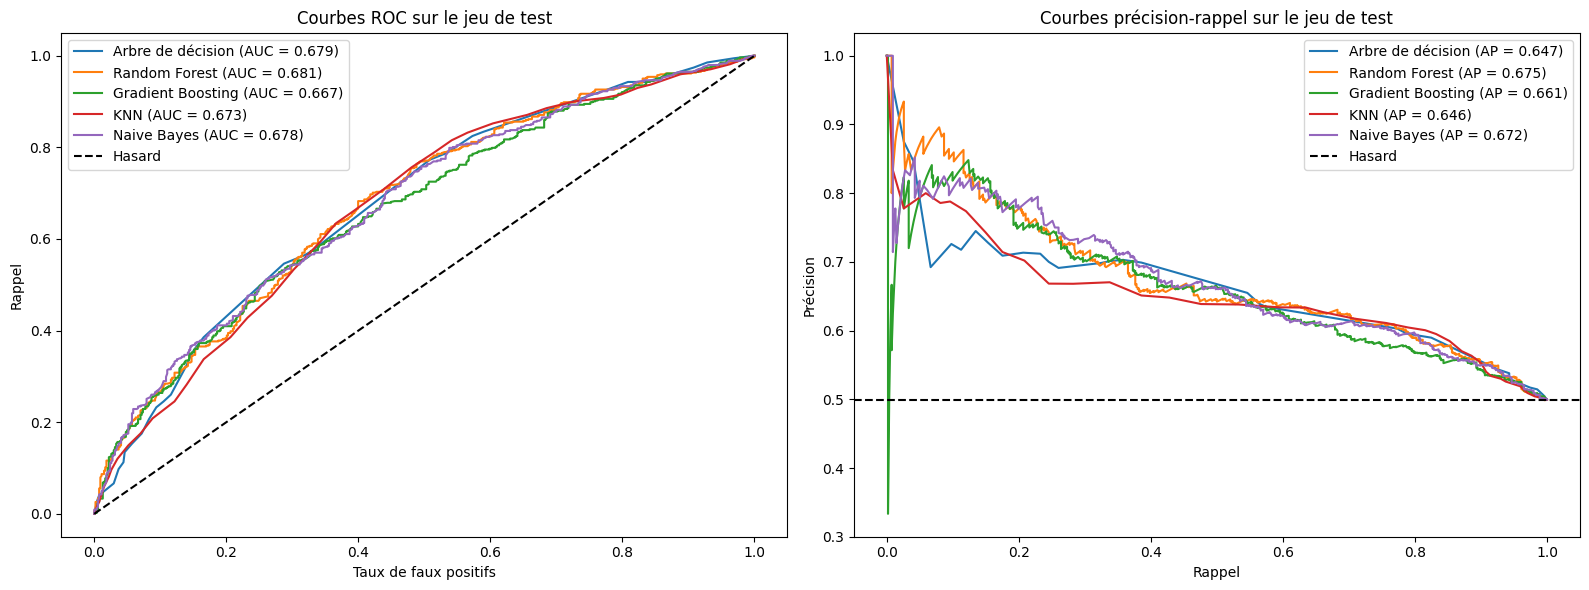

In [55]:
probabilites_test = {}
accuracy_test = {}
for nom, modele in modeles.items():
    pipeline = Pipeline([('preparation', preparation), ('modele', modele)])
    pipeline.fit(X_train, y_train)
    probabilites_test[nom] = pipeline.predict_proba(X_test)[:, 1]
    accuracy_test[nom] = accuracy_score(y_test, pipeline.predict(X_test))

print(pd.Series(accuracy_test, name='Accuracy sur le test').round(3).sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for nom, proba in probabilites_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{nom} (AP = {average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Hasard')
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Rappel")
axes[0].set_title("Courbes ROC sur le jeu de test")
axes[0].legend()

axes[1].axhline(y_test.mean(), color='black', linestyle='--', label='Hasard')
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbes précision-rappel sur le jeu de test")
axes[1].legend()

plt.tight_layout()
plt.show()

Sur le jeu de test, la **Random Forest** a la **meilleure accuracy** (0.640), devant le KNN (0.637), l'arbre de décision (0.627), le Gradient Boosting (0.618) et Naive Bayes (0.615). Le choix fait à la Partie 5 est donc **confirmé** sur des données jamais vues.

Les écarts entre algorithmes restent petits : c'est la conséquence des liens faibles entre les variables et la cible, observés dès la matrice de corrélation.

## 3. Stabilité du modèle

Un bon modèle doit donner des scores **proches** d'un découpage des données à l'autre. On regarde la moyenne et l'**écart-type** des scores sur les 5 plis de la validation croisée. Un petit écart-type signifie que le modèle est stable.

In [56]:
scores_stabilite = cross_validate(modele_choisi, X_train, y_train, cv=validation, scoring=mesures)

stabilite = pd.DataFrame({
    'Moyenne': [scores_stabilite['test_' + m].mean() for m in mesures],
    'Écart-type': [scores_stabilite['test_' + m].std() for m in mesures]
}, index=list(mesures)).round(3)
stabilite

,Moyenne,Écart-type
Accuracy,0.651,0.014
Rappel,0.697,0.025
Précision,0.639,0.017
F1,0.666,0.013
ROC-AUC,0.706,0.010


L'écart-type de l'accuracy est de **0.014** : d'un découpage à l'autre, l'accuracy varie d'environ 1 point seulement. Le modèle est **stable**, on peut donc faire confiance à ses résultats.

## 4. Choix du seuil de décision

Par défaut, le modèle répond « a des gains » si la probabilité est d'au moins **0.5**. Ce seuil peut être changé :
* un seuil **plus bas** trouve plus de personnes avec gains (rappel plus haut), mais fait plus d'erreurs sur les personnes sans gains ;
* un seuil **plus haut** fait l'inverse.

On cherche le seuil qui donne la **meilleure accuracy**.

**Important :** on choisit le seuil sur le jeu d'**entraînement** (avec `cross_val_predict`), pour ne pas tricher avec le jeu de test.

In [57]:
probabilites_train = cross_val_predict(modele_choisi, X_train, y_train, cv=validation, method='predict_proba')[:, 1]

lignes = []
for seuil in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    pred = (probabilites_train >= seuil).astype(int)
    lignes.append([seuil, accuracy_score(y_train, pred), recall_score(y_train, pred),
                   precision_score(y_train, pred, zero_division=0), f1_score(y_train, pred)])

tableau_seuils = pd.DataFrame(lignes, columns=['Seuil', 'Accuracy', 'Rappel', 'Précision', 'F1']).round(3)
tableau_seuils

,Seuil,Accuracy,Rappel,Précision,F1
0,0.30,0.574,0.956,0.542,0.692
1,0.35,0.600,0.917,0.561,0.696
2,0.40,0.628,0.866,0.587,0.700
3,0.45,0.646,0.801,0.611,0.693
4,0.50,0.651,0.697,0.638,0.666
5,0.55,0.643,0.549,0.677,0.606
6,0.60,0.612,0.382,0.708,0.497
7,0.65,0.586,0.256,0.754,0.382
8,0.70,0.546,0.131,0.776,0.224


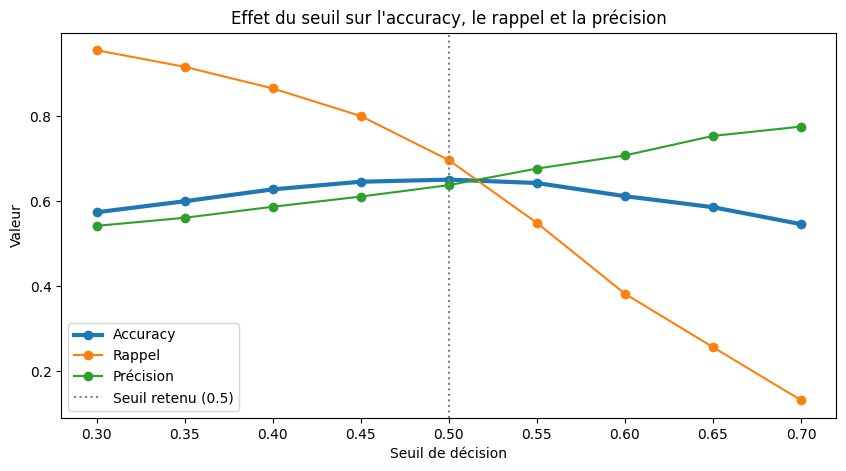

Seuil qui donne la meilleure accuracy : 0.5


In [58]:
seuil_retenu = tableau_seuils.loc[tableau_seuils['Accuracy'].idxmax(), 'Seuil']

plt.figure(figsize=(10, 5))
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Accuracy'], marker='o', linewidth=3, label='Accuracy')
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Rappel'], marker='o', label='Rappel')
plt.plot(tableau_seuils['Seuil'], tableau_seuils['Précision'], marker='o', label='Précision')
plt.axvline(seuil_retenu, color='grey', linestyle=':', label=f'Seuil retenu ({seuil_retenu})')
plt.xlabel("Seuil de décision")
plt.ylabel("Valeur")
plt.title("Effet du seuil sur l'accuracy, le rappel et la précision")
plt.legend()
plt.show()

print("Seuil qui donne la meilleure accuracy :", seuil_retenu)

**Lecture du tableau :**
* La meilleure accuracy (**0.651**) est obtenue avec le seuil **0.50**, le seuil par défaut. On le garde donc.
* Le seuil **0.45** donne une accuracy presque identique (0.646) avec un rappel bien plus haut (0.801). Si l'organisme préfère trouver plus de personnes avec gains, quitte à contacter plus de monde, il peut choisir ce seuil.
* Au-dessus de 0.55, l'accuracy baisse vite, car le modèle manque beaucoup de personnes avec gains (le rappel chute).

On vérifie l'accuracy du seuil retenu sur le jeu de test :

In [59]:
predictions_seuil = (probabilites >= seuil_retenu).astype(int)

print("Seuil retenu :", seuil_retenu)
print("Accuracy sur le test :", round(accuracy_score(y_test, predictions_seuil), 3))

Seuil retenu : 0.5
Accuracy sur le test : 0.64


Avec le seuil retenu (0.5), l'accuracy sur le test est de **0.640**, comme à la Partie 5. Le seuil par défaut était déjà le meilleur choix pour l'accuracy.

## 5. Courbe de gain cumulé

Cette courbe répond à la question : *si l'organisme contacte les X % de personnes les plus probables selon le modèle, quel pourcentage des personnes avec gains atteint-il ?*

* La **diagonale** correspond à un ciblage au hasard.
* Plus la courbe du modèle est **au-dessus** de la diagonale, plus le ciblage est efficace.

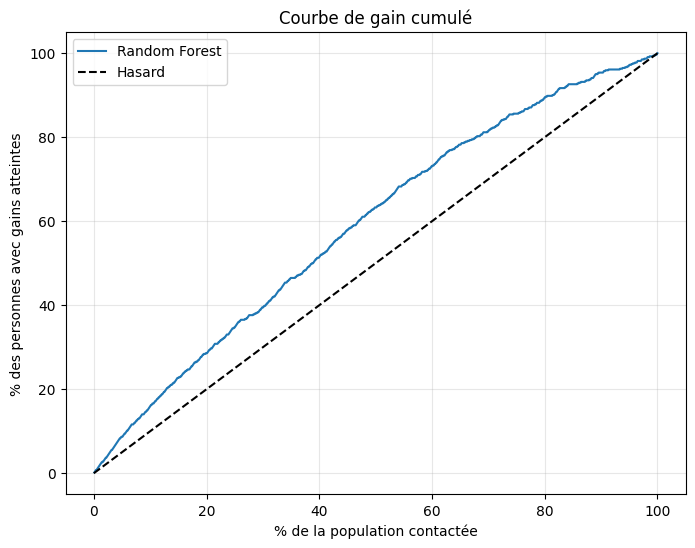

,% contactés,% de personnes avec gains atteintes,Gain par rapport au hasard
0,10,15.9,1.59
1,20,28.6,1.43
2,30,39.5,1.32
3,40,51.5,1.29
4,50,63.3,1.27


In [60]:
ordre = np.argsort(-probabilites)
gains_cumules = np.cumsum(y_test.values[ordre]) / y_test.sum()
part_contactee = np.arange(1, len(ordre) + 1) / len(ordre)

plt.figure(figsize=(8, 6))
plt.plot(part_contactee * 100, gains_cumules * 100, label='Random Forest')
plt.plot([0, 100], [0, 100], 'k--', label='Hasard')
plt.xlabel("% de la population contactée")
plt.ylabel("% des personnes avec gains atteintes")
plt.title("Courbe de gain cumulé")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

tableau_gain = pd.DataFrame({
    '% contactés': [10, 20, 30, 40, 50],
    '% de personnes avec gains atteintes': [round(gains_cumules[int(len(ordre) * p / 100) - 1] * 100, 1) for p in [10, 20, 30, 40, 50]]
})
tableau_gain['Gain par rapport au hasard'] = (tableau_gain['% de personnes avec gains atteintes'] / tableau_gain['% contactés']).round(2)
tableau_gain

En contactant **20 %** des personnes du test, l'organisme atteint environ **28 %** des personnes avec gains, soit **1.4 fois mieux** que le hasard. En contactant **50 %**, il en atteint environ **63 %**.

Le gain est le plus fort pour les premiers pourcentages contactés : le modèle est surtout utile pour repérer les profils **les plus** probables.

## 6. Courbe d'apprentissage

Cette courbe montre l'évolution de l'accuracy quand on entraîne le modèle avec de plus en plus de données :
* si l'écart entre entraînement et validation est **grand**, le modèle apprend par cœur (sur-apprentissage) ;
* si la courbe de validation **monte encore**, plus de données amélioreraient le modèle ;
* si elle est **plate**, ajouter des personnes ne servirait presque à rien.

(Cette cellule peut prendre environ une minute.)

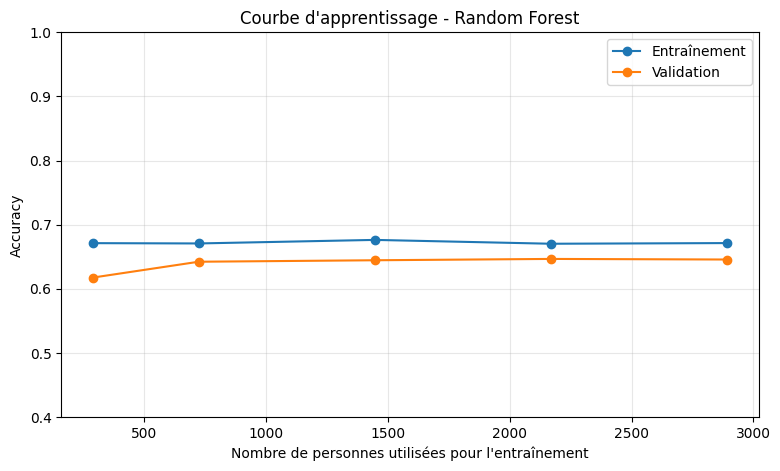

In [61]:
tailles, scores_train, scores_validation = learning_curve(
    modele_choisi, X_train, y_train, cv=3, scoring='accuracy',
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], n_jobs=-1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, scores_train.mean(axis=1), marker='o', label='Entraînement')
plt.plot(tailles, scores_validation.mean(axis=1), marker='o', label='Validation')
plt.xlabel("Nombre de personnes utilisées pour l'entraînement")
plt.ylabel("Accuracy")
plt.title("Courbe d'apprentissage - Random Forest")
plt.ylim(0.4, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Lecture :**
* L'écart entre entraînement (≈ 0.67) et validation (≈ 0.65) est **petit** et diminue : il n'y a pas de sur-apprentissage.
* La courbe de validation monte au début, puis devient **presque plate** à partir d'environ 2 000 personnes.

**Conclusion :** ajouter des personnes au dataset n'améliorerait presque pas le modèle. Pour faire mieux, il faudrait **d'autres variables** (patrimoine, épargne, héritage), ce qui confirme la limite observée dès la matrice de corrélation.

## 7. Le modèle est-il équitable ? Analyse par groupe

L'organisme ne doit pas oublier certains publics dans ses actions de sensibilisation. On calcule donc l'**accuracy** et le **rappel** du modèle pour chaque groupe.

Le modèle n'utilise pas la variable `sex` (exclue à la Partie 4), mais on la récupère dans `df_texte` pour **vérifier** que le modèle ne défavorise pas un groupe.

In [62]:
analyse = X_test.copy()
analyse['sex'] = df_texte.loc[X_test.index, 'sex']
analyse['reel'] = y_test.values
analyse['predit'] = predictions

def resume_groupe(groupe):
    return pd.Series({
        'Nombre de personnes': len(groupe),
        'Accuracy': round(accuracy_score(groupe['reel'], groupe['predit']), 3),
        'Taux réel avec gains': round(groupe['reel'].mean(), 3),
        'Rappel': round(recall_score(groupe['reel'], groupe['predit'], zero_division=0), 3),
        'Part ciblée': round(groupe['predit'].mean(), 3)
    })

print("Par sexe :")
display(analyse.groupby('sex')[['reel', 'predit']].apply(resume_groupe))
print("Par tranche d'âge :")
display(analyse.groupby('tranche_age')[['reel', 'predit']].apply(resume_groupe))

Par sexe :


,Nombre de personnes,Accuracy,Taux réel avec gains,Rappel,Part ciblée
sex,,,,,
Female,322.0,0.671,0.425,0.562,0.382
Male,763.0,0.626,0.531,0.723,0.611


Par tranche d'âge :


,Nombre de personnes,Accuracy,Taux réel avec gains,Rappel,Part ciblée
tranche_age,,,,,
17-25,152.0,0.730,0.276,0.048,0.020
26-35,244.0,0.615,0.422,0.505,0.389
36-45,306.0,0.624,0.549,0.762,0.663
46-55,219.0,0.616,0.580,0.827,0.763
56-65,104.0,0.673,0.606,0.794,0.683
66+,60.0,0.617,0.650,0.846,0.833


**Lecture :**
* **Par sexe :** le modèle n'utilise pas la variable `sex`, mais on vérifie quand même ses résultats pour chaque groupe. Il trouve environ **72 %** des hommes avec gains et environ **56 %** des femmes. Une partie de l'écart vient de la réalité (dans le jeu de test, les femmes ont moins souvent des gains : 43 % contre 53 %) et des autres variables, comme `est_marie`.
* **Par âge :** l'accuracy est la plus haute chez les 17-25 ans (0.73), mais seulement parce que le modèle répond presque toujours « non » pour eux : il ne trouve que **5 %** des jeunes avec gains.

C'est un **point d'attention pour l'organisme** : des femmes et des jeunes qui ont des revenus du capital risquent de ne pas recevoir les actions de sensibilisation. Or les jeunes sont justement un public intéressant pour l'éducation à l'épargne.

On retrouve ici la même leçon qu'avec les données réelles : une bonne accuracy dans un groupe peut cacher un modèle qui répond toujours « non ».

### Vérification : et si on avait gardé `sex` ?

À la Partie 4, on a exclu `sex` car c'est une variable sensible. On vérifie que ce choix ne fait pas perdre de performance : on entraîne le même modèle **avec** `sex` et on compare.

In [63]:
variables_avec_sexe = variables_categorielles + ['sex']

preparation_avec_sexe = ColumnTransformer([
    ('texte', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variables_avec_sexe),
    ('nombres', StandardScaler(), variables_numeriques_modele)
])
modele_avec_sexe = Pipeline([('preparation', preparation_avec_sexe), ('modele', modeles['Random Forest'])])

X_train_avec_sexe = df_texte.loc[X_train.index, variables_avec_sexe + variables_numeriques_modele]
X_test_avec_sexe = df_texte.loc[X_test.index, variables_avec_sexe + variables_numeriques_modele]
modele_avec_sexe.fit(X_train_avec_sexe, y_train)

proba_avec_sexe = modele_avec_sexe.predict_proba(X_test_avec_sexe)[:, 1]
pred_avec_sexe = (proba_avec_sexe >= 0.5).astype(int)
femmes = (analyse['sex'] == 'Female').values

comparaison = pd.DataFrame({
    'Modèle final (sans sex)': [accuracy_score(y_test, predictions), roc_auc_score(y_test, probabilites),
                                recall_score(y_test, predictions), f1_score(y_test, predictions),
                                recall_score(y_test[femmes], predictions[femmes])],
    'Si on gardait sex': [accuracy_score(y_test, pred_avec_sexe), roc_auc_score(y_test, proba_avec_sexe),
                          recall_score(y_test, pred_avec_sexe), f1_score(y_test, pred_avec_sexe),
                          recall_score(y_test[femmes], pred_avec_sexe[femmes])]
}, index=['Accuracy', 'ROC-AUC', 'Rappel', 'F1', 'Rappel chez les femmes']).round(3)
comparaison

,Modèle final (sans sex),Si on gardait sex
Accuracy,0.640,0.633
ROC-AUC,0.681,0.680
Rappel,0.683,0.675
F1,0.654,0.648
Rappel chez les femmes,0.562,0.445


Le modèle final, **sans** `sex`, a une **meilleure accuracy** (0.640 contre 0.633) et un meilleur F1. Surtout, il trouve beaucoup mieux les femmes avec gains : **56 %** contre **45 %** si on avait gardé `sex`.

**Conclusion :** exclure la variable sensible `sex` ne coûte rien en performance et rend le ciblage plus équitable. Ce choix fait à la Partie 4 est donc confirmé. L'écart restant entre hommes et femmes vient de la réalité des données et d'autres variables (par exemple `est_marie`) : l'organisme pourrait le compenser par des actions spécifiques pour les femmes et les jeunes.

# Conclusion de l'évaluation

| Point vérifié | Résultat |
|---|---|
| Rapport de classification | Accuracy de 0.64, scores proches pour les deux classes grâce à l'équilibrage |
| Comparaison sur le test | La Random Forest a la meilleure accuracy (0.640) : le choix est confirmé |
| Stabilité | Écart-type de l'accuracy de 0.014 : le modèle est stable |
| Seuil de décision | Le seuil par défaut **0.5** donne la meilleure accuracy |
| Courbe de gain | 20 % des personnes contactées → 28 % des personnes avec gains atteintes (1.4 fois mieux que le hasard) |
| Courbe d'apprentissage | Pas de sur-apprentissage ; plus de données n'aideraient presque pas, il faut d'autres variables |
| Équité | Sans `sex`, l'accuracy est meilleure (0.640 contre 0.633) et le modèle trouve mieux les femmes (56 % contre 45 %) ; les jeunes restent mal repérés |

**Bilan :** sur des données équilibrées, la Random Forest classe correctement environ **64 %** des personnes, contre 50 % au hasard, sans utiliser de variable sensible. Elle ne prédit pas avec certitude, car les variables du dataset expliquent peu la présence de gains en capital, mais elle aide l'organisme à **prioriser** ses actions de sensibilisation. On recommande une attention particulière aux publics jeunes et féminins.